# Parkinson's voice biomarkers, tested on unseen subjects

Can sustained-vowel measurements tell people with Parkinson's disease apart from healthy controls **when every recording from a person is held out together**?

Each subject in the UCI Parkinsons file contributes six or seven phonations. A random split of rows can place the same voice in the training set and the test set, and the accuracy from that split is not an estimate for a new person. The models below are scored with subject-grouped stratified cross-validation, next to a majority-class baseline.

This notebook calls `src/`. The tables in `results/` are written by `python src/train.py` from the repository root.


In [1]:
%matplotlib inline

from pathlib import Path
import subprocess
import sys

def find_root() -> Path:
    """Repository root when the notebook is run locally, or a fresh clone on Colab."""
    here = Path.cwd().resolve()
    for candidate in [here, *here.parents]:
        data = candidate / "data" / "raw" / "parkinsons.data"
        train = candidate / "src" / "train.py"
        if data.is_file() and train.is_file():
            return candidate
    dest = Path("/content/parkinsons-voice-biomarker-ml")
    if not (dest / "data" / "raw" / "parkinsons.data").is_file():
        subprocess.run(
            [
                "git",
                "clone",
                "--depth",
                "1",
                "https://github.com/Ishitta-Sarkar/parkinsons-voice-biomarker-ml.git",
                str(dest),
            ],
            check=True,
        )
    return dest

ROOT = find_root()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt

from src.data_loader import (
    algebraic_duplicate_gap,
    cohort_summary,
    design_matrix,
    load_parkinsons,
)
from src.train import (
    N_ESTIMATORS,
    evaluate_grouped,
    evaluate_holdout,
    evaluate_record_level,
    grouped_splitter,
    permutation_importance_grouped,
    recording_holdout_indices,
    recording_splitter,
    subject_leakage,
    summary_lines,
    HOLDOUT_PROTOCOL,
)
from src.visualization import (
    write_correlation_figure,
    write_cv_figure,
    write_importance_figure,
    write_sample_distribution,
    write_subject_median_figure,
)

frame = load_parkinsons()
features, labels, groups = design_matrix(frame)
print(f"Loaded {frame.shape[0]} recordings and {frame.shape[1]} columns")


Loaded 195 recordings and 24 columns


## Cohort

The UCI catalogue text says the table holds 31 people, 23 with Parkinson's disease. The subject token is parsed from `name` (`phon_R01_S01_1` → `S01`). The counts printed below are what that parser returns on this file, and they are the groups used for cross-validation.


In [2]:
summary = cohort_summary(frame)
for key, value in summary.items():
    print(f"{key}: {value}")

gaps = algebraic_duplicate_gap(frame)
print("max |Jitter:DDP - 3*MDVP:RAP|:", f"{gaps['jitter_ddp_minus_3rap_max_abs']:.3e}")
print("max |Shimmer:DDA - 3*Shimmer:APQ3|:", f"{gaps['shimmer_dda_minus_3apq3_max_abs']:.3e}")


n_recordings: 195
n_columns: 24
n_features: 22
n_subjects: 32
n_pd_subjects: 24
n_healthy_subjects: 8
n_pd_recordings: 147
n_healthy_recordings: 48
recordings_per_subject_min: 6
recordings_per_subject_max: 7
max |Jitter:DDP - 3*MDVP:RAP|: 1.000e-05
max |Shimmer:DDA - 3*Shimmer:APQ3|: 1.000e-05


`Jitter:DDP` and `Shimmer:DDA` are three times two other columns, up to the rounding stored in the file. They are not independent measurements.

The bars below count recordings and subjects separately. Most of the mass is Parkinson's disease in both units, so a classifier that always predicts PD is already accurate on about three quarters of the rows.


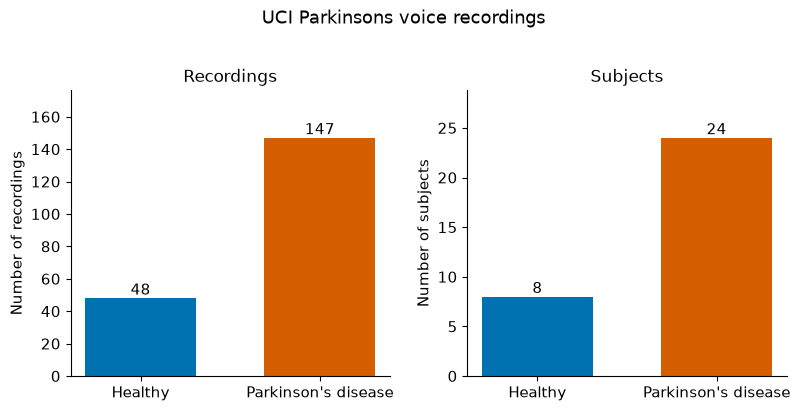

In [3]:
fig = write_sample_distribution(frame)
plt.show()


## Subject-level features

Plots in this section use the median of each subject's recordings. A recording-level plot would treat six takes from one person as six independent people.

The six panels are one column from each family that ships with the UCI table (fundamental frequency, jitter, shimmer, harmonics-to-noise ratio, RPDE, pitch period entropy). They were not picked by ranking a fitted model.


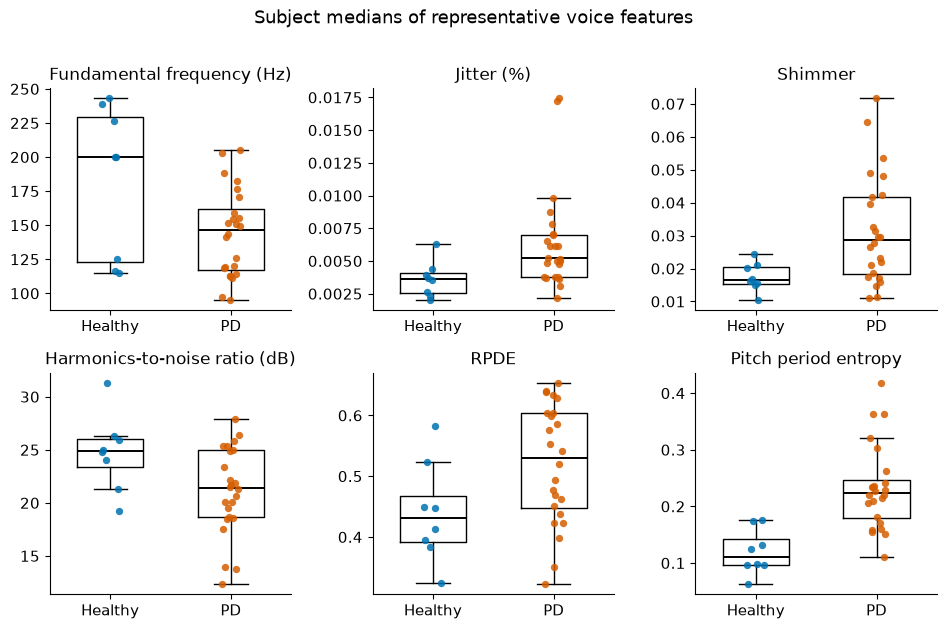

In [4]:
fig = write_subject_median_figure(frame)
plt.show()


Pearson correlations of those subject medians. Jitter columns move together, and shimmer columns move together, which is what the duplicate identities above already imply.


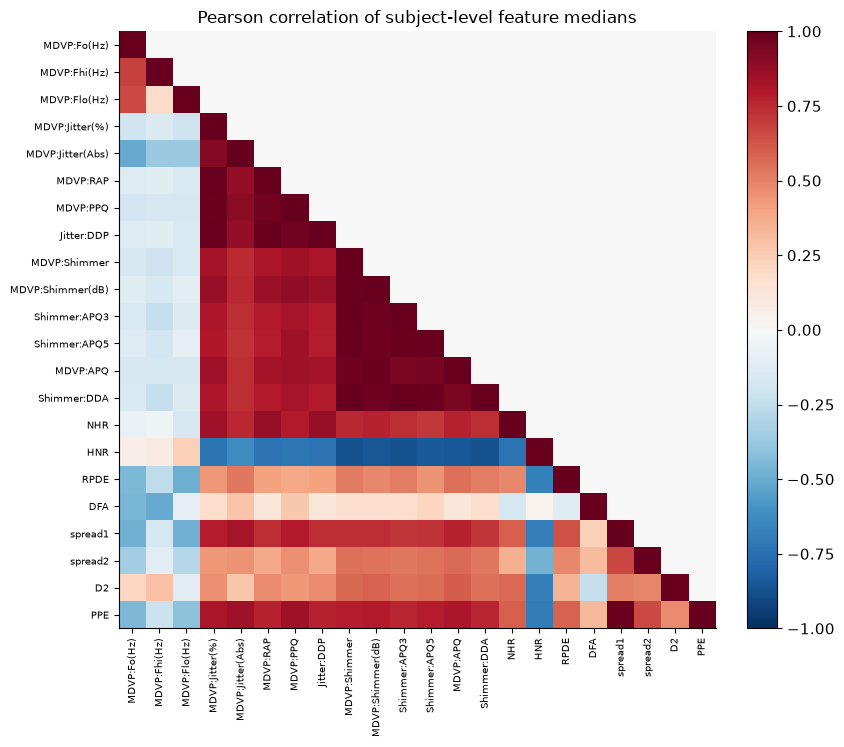

In [5]:
fig = write_correlation_figure(frame)
plt.show()


## The same subject on both sides of a split

Two recording-level protocols are checked before any model is fit. `n_subjects_in_both` is the number of subject ids that appear in training and in test. `fraction_test_recordings_seen_in_train` is the share of test rows whose subject was also seen in training.


In [6]:
train_idx, test_idx = recording_holdout_indices(labels)
holdout_leak = subject_leakage(groups, train_idx, test_idx)
print("Stratified 80/20 split of recordings (random_state=42)")
for key, value in holdout_leak.items():
    print(f"  {key}: {value}")

print("Recording-level stratified 5-fold")
for fold, (tr, te) in enumerate(recording_splitter().split(features, labels), start=1):
    leak = subject_leakage(groups, tr, te)
    print(
        f"  fold {fold}: subjects in both={leak['n_subjects_in_both']}, "
        f"fraction of test recordings seen in training="
        f"{leak['fraction_test_recordings_seen_in_train']:.3f}"
    )

print("Subject-grouped stratified 5-fold")
grouped_overlaps = []
for fold, (tr, te) in enumerate(grouped_splitter().split(features, labels, groups), start=1):
    leak = subject_leakage(groups, tr, te)
    grouped_overlaps.append(leak["n_subjects_in_both"])
    print(
        f"  fold {fold}: subjects in both={leak['n_subjects_in_both']}, "
        f"test subjects={leak['n_test_subjects']}"
    )
if any(grouped_overlaps):
    raise RuntimeError("A grouped fold shares a subject between train and test.")


Stratified 80/20 split of recordings (random_state=42)
  n_train: 156
  n_test: 39
  n_train_subjects: 32
  n_test_subjects: 24
  n_subjects_in_both: 24
  fraction_test_recordings_seen_in_train: 1.0
Recording-level stratified 5-fold
  fold 1: subjects in both=25, fraction of test recordings seen in training=1.000
  fold 2: subjects in both=26, fraction of test recordings seen in training=1.000
  fold 3: subjects in both=23, fraction of test recordings seen in training=1.000
  fold 4: subjects in both=26, fraction of test recordings seen in training=1.000
  fold 5: subjects in both=23, fraction of test recordings seen in training=1.000
Subject-grouped stratified 5-fold
  fold 1: subjects in both=0, test subjects=6
  fold 2: subjects in both=0, test subjects=7
  fold 3: subjects in both=0, test subjects=6
  fold 4: subjects in both=0, test subjects=7
  fold 5: subjects in both=0, test subjects=6


## Models

Three estimators, chosen before looking at the test folds:

- Majority baseline: predict the class that is most common in the training fold.
- L2 logistic regression (`C=1`) on features standardised inside the training fold.
- Random forest with 500 trees and `random_state=42`.

`StratifiedGroupKFold` (5 folds, shuffle, seed 42) keeps every recording from a subject on one side of the fold. The positive class is Parkinson's disease. The printed line is the mean ± the sample standard deviation of the five fold scores. ROC-AUC is undefined for the baseline because that score does not vary. ROC-AUC is the primary comparison: accuracy stays high if the model calls almost every recording PD.


Subject-grouped 5-fold CV
majority_baseline | 0.756 ± 0.074 | 0.500 ± 0.000 | undefined | 0.860 ± 0.048
logistic_regression | 0.787 ± 0.092 | 0.652 ± 0.199 | 0.736 ± 0.189 | 0.865 ± 0.056
random_forest | 0.786 ± 0.071 | 0.604 ± 0.125 | 0.817 ± 0.041 | 0.864 ± 0.057


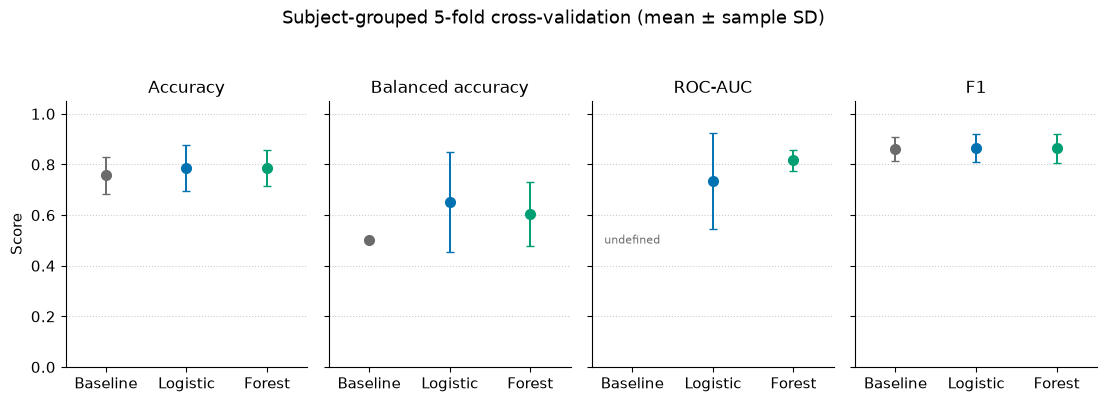

In [7]:
grouped_summary, grouped_folds = evaluate_grouped(features, labels, groups)
print("Subject-grouped 5-fold CV")
for line in summary_lines(grouped_summary):
    print(line)
if int(grouped_folds["n_subjects_in_both"].max()) != 0:
    raise RuntimeError("Grouped evaluation leaked a subject.")
fig = write_cv_figure(grouped_summary)
plt.show()


Read against the baseline, not against 1. Accuracy and F1 for both fitted models sit next to the majority classifier: the forest accuracy is 0.786 ± 0.071 and the baseline is 0.756 ± 0.074. Balanced accuracy leaves the baseline value of 0.500 (logistic regression 0.652 ± 0.199, forest 0.604 ± 0.125), and those standard deviations are large because several test folds have only six healthy recordings. The forest ROC-AUC is 0.817 ± 0.041. The logistic regression ROC-AUC is 0.736 ± 0.189. Held-out subjects are ranked better than chance. The separation is modest, and a hard threshold does not beat "everyone has PD" by a margin that survives the fold scatter.


## The inflated comparison

The same three models on a stratified 5-fold split of *recordings* still share subjects on every fold. The 80/20 row refits the 500-tree forest on that single leaked split. Both are reported so the grouped table is not confused with them.


In [8]:
record_summary, _record_folds = evaluate_record_level(features, labels, groups)
print("Recording-level 5-fold CV (subjects leak)")
for line in summary_lines(record_summary):
    print(line)

holdout = evaluate_holdout(
    features,
    labels,
    groups,
    n_estimators=N_ESTIMATORS,
    protocol=HOLDOUT_PROTOCOL,
)
print("Recording-level 80/20, 500-tree forest")
print(
    f"  accuracy={holdout['accuracy']:.3f} "
    f"balanced_accuracy={holdout['balanced_accuracy']:.3f} "
    f"roc_auc={holdout['roc_auc']:.3f} "
    f"f1={holdout['f1']:.3f}"
)
print(
    f"  subjects in both={holdout['n_subjects_in_both']}, "
    f"fraction of test recordings seen in training="
    f"{holdout['fraction_test_recordings_seen_in_train']:.3f}"
)


Recording-level 5-fold CV (subjects leak)
majority_baseline | 0.754 ± 0.014 | 0.500 ± 0.000 | undefined | 0.860 ± 0.009
logistic_regression | 0.867 ± 0.056 | 0.795 ± 0.088 | 0.905 ± 0.047 | 0.913 ± 0.036
random_forest | 0.887 ± 0.069 | 0.824 ± 0.130 | 0.958 ± 0.030 | 0.928 ± 0.043


Recording-level 80/20, 500-tree forest
  accuracy=0.923 balanced_accuracy=0.883 roc_auc=0.972 f1=0.949
  subjects in both=24, fraction of test recordings seen in training=1.000


Recording-level forest ROC-AUC is 0.958 ± 0.030 and the 80/20 accuracy is 0.923. Every test recording in that holdout belongs to a subject who is also in the training set. That is the quantity a recording-level split was measuring.


## Permutation importance

For each grouped test fold the fitted model is held fixed and one column is shuffled. The importance is the drop in ROC-AUC, averaged over 20 shuffles and then over the five folds. Whiskers are the sample standard deviation across folds.


Random forest, largest mean drops in ROC-AUC
  spread1: 0.061 ± 0.041
  PPE: 0.050 ± 0.029
  spread2: 0.025 ± 0.021
  D2: 0.018 ± 0.011
  MDVP:Fo(Hz): 0.010 ± 0.024
  MDVP:APQ: 0.009 ± 0.017


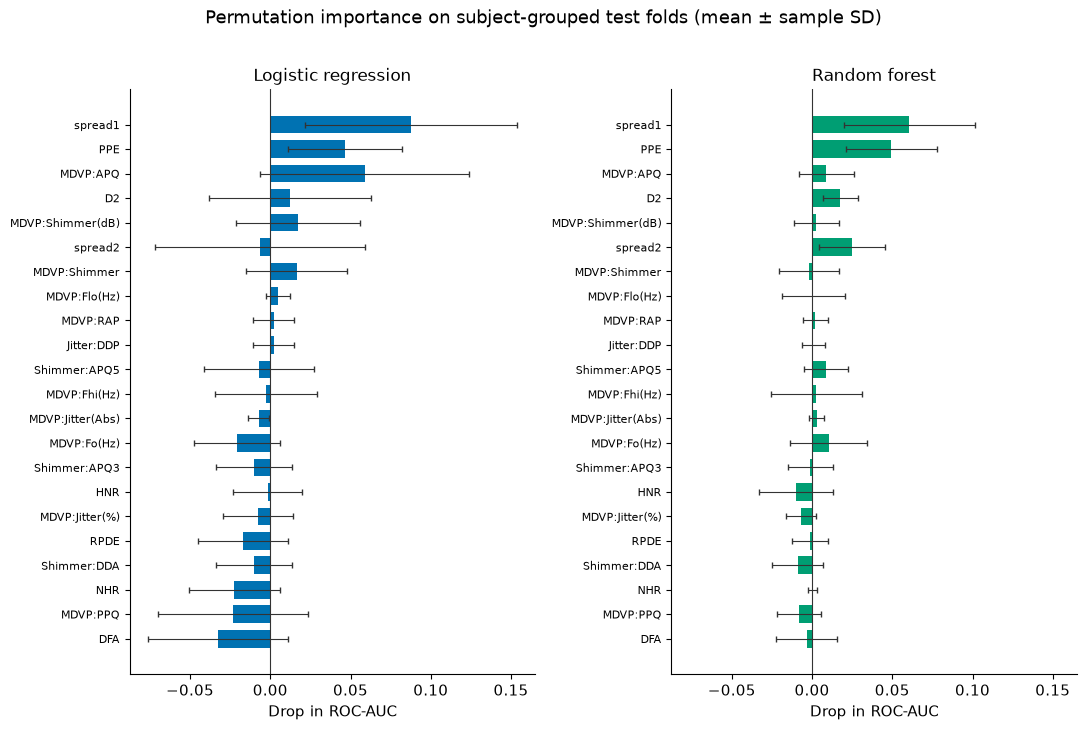

In [9]:
importance = permutation_importance_grouped(features, labels, groups)
forest = importance.loc[importance["model"] == "random_forest"].sort_values(
    "importance_mean", ascending=False
)
print("Random forest, largest mean drops in ROC-AUC")
for row in forest.head(6).itertuples(index=False):
    print(f"  {row.feature}: {row.importance_mean:.3f} ± {row.importance_std:.3f}")
fig = write_importance_figure(importance)
plt.show()


`spread1` and `PPE` are the largest mean drops for the forest (0.061 ± 0.041 and 0.050 ± 0.029). The logistic regression ranks the same two columns highly, with fold standard deviations that are as large as the means. Duplicate jitter and shimmer columns should not be read as separate effects. On 32 subjects this is a description of the sample, not a biomarker that has been confirmed anywhere else.


## Limitations

The file has 32 subject ids and one phonation task. Grouped cross-validation blocks a trivial form of leakage. It is not an external test. No age, sex, severity, or medication is available, and nothing here is a diagnostic or a screening result. Settings were fixed in advance (`C=1`, 500 trees, seed 42) and were not tuned on these folds.

Regenerate the committed tables and figures with `python src/train.py`.
